## Implementation of Linear regression using python

In [67]:
### import required libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score
import matplotlib.pyplot as plt


## Load the dataset

In [41]:
DF1=pd.read_csv("weight-height.csv")
DF1.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


### Standardize numerical features

In [42]:
col=["Height","Weight"]
S1=MinMaxScaler()
DF1[col]=S1.fit_transform(DF1[col])
DF1.head()


,Gender,Height,Weight
0,Male,0.165212,0.863139
1,Male,0.122482,0.475476
2,Male,0.167432,0.721131
3,Male,0.147361,0.756699
4,Male,0.131761,0.689999


## Prepare dependant and independant variables

In [43]:
X=DF1[["Height"]].to_numpy()
Y=DF1[["Weight"]].to_numpy()
Y.shape

(10000, 1)

## Split the data into training and test set

In [44]:
 X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=.2,random_state=67)

In [45]:
# Create a linear regression model

model=LinearRegression()



Note: Learning more about Linear Regression model here: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html 



In [46]:
## Training  Linear regressions model 

In [47]:
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[3.55]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[0.11]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.28]


In [48]:
## Calculating the Mean Squared Error (MSE) and R-squared (R2)
Y_pred=model.predict(X_test)
mse=mean_squared_error(Y_test,Y_pred)
rmse = mean_squared_error(Y_test, Y_pred) ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2=r2_score(Y_test,Y_pred)
print(mse)
print(rmse)

print(mae)
print(r2)

# Print model coefficients
print(model.coef_[0])
print(model.intercept_)

0.004438047889011701
0.06661867522708403
0.05448015043349381
0.81352993734737
[3.54709605]
[0.10829265]


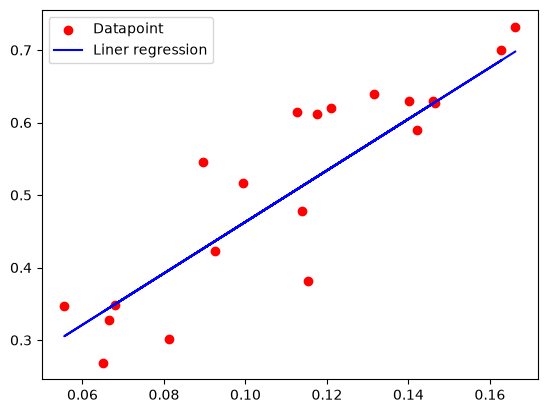

In [49]:
# Plot the linear regression Model 
plt.scatter(X_test[0:20],Y_test[0:20],color="Red",label="Datapoint")
plt.plot(X_test[0:20],Y_pred[0:20],color="Blue",label="Liner regression")
plt.legend()


In [50]:
## Load the Height and weight  to indipendent and dependent variable 

### Z-Score Normalization

The Z-score normalization formula is:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:
- $x$ = Original data value
- $\mu$ = Mean of the dataset
- $\sigma$ = Standard deviation of the dataset
- $z$ = Normalized Z-score

In [51]:
## Standardizes the features X and target variable y using Z-score normalization (also called Standardization). 
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
Y = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


[![Single-Input-Linear-Neuron-Diagram.png](https://i.postimg.cc/PxYWMz4F/Single-Input-Linear-Neuron-Diagram.png)](https://postimg.cc/vg8xYnCW)

In [52]:
#add another feature to X corresponding to bias
X = np.hstack((np.ones((X.shape[0], 1)), X))
X

array([[ 1.        ,  1.75827913],
       [ 1.        ,  0.56277158],
       [ 1.        ,  1.82037531],
       ...,
       [ 1.        , -0.59704831],
       [ 1.        , 24.22511229],
       [ 1.        , -1.05110595]], shape=(10000, 2))

In [53]:
#weight or parameter initialization
theta = np.zeros(X.shape[1])
iterations=1000
# Hyperparameters
learningrate=0.01
# Gradient Descent
mseh=[]
print(X.shape)
m=X.T
print(m.shape)


(10000, 2)
(2, 10000)


<img src="https://i.postimg.cc/wMYVXD65/1.png" alt="Image Description" width="500">

In [60]:

for i in range(iterations):
    y_pred = np.dot(X, theta)

    mse = mean_squared_error(Y, y_pred)
    mseh.append(mse)
    print(f"Iteration {i+1}: MSE = {mse}")
    gradient = np.dot(X.T, (y_pred - Y)) / len(Y)
    theta = theta- (learningrate * gradient)
print("Final theta:", theta)


Iteration 1: MSE = 1.0


ValueError: operands could not be broadcast together with shapes (2,) (2,10000) 

In [55]:
print("Final theta:", theta)

Final theta: [0. 0.]


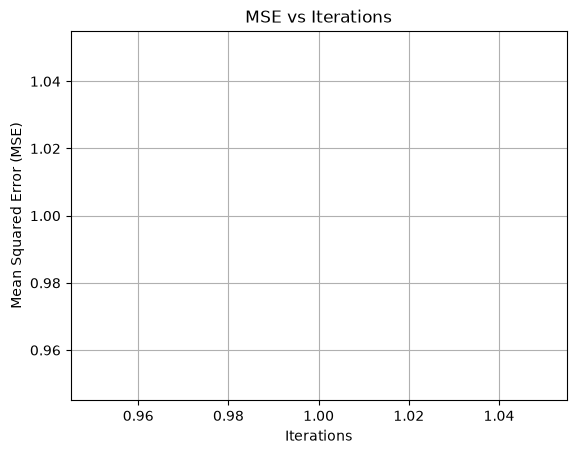

In [56]:

plt.plot(range(1, len(mseh) + 1), mseh)

plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("MSE vs Iterations")
plt.grid(True)

plt.show()


## You are required to fit a linear function on Food_delivery_times dataset
Description about the dataset: This dataset is designed for predicting food delivery times based on various influencing factors such as distance, weather, traffic conditions, and Preperation time. 
1. Feature selection: Consider Food_delivery_time is effected by four features (attributes) given in the dataset, which are Distance_km, Preparation_Time_min, Traffic, Weather
2. Since Traffic, Weather are having categorical values, you need to convert them into numerical using the categorical encoding methods.
3. Now, fit a linear regression model considering Distance_km, Preparation_Time_min, Traffic, and Weather as independant variables and Delivery_Time_min as dependant varibal. 


Note: In lab record, you can write the statements relevant to linear regression.

In [73]:
#load the dataset

In [76]:
DF1 = pd.read_csv("Food_Delivery_Times.csv")
DF1.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [77]:
# Feature selection and categorical encoding

col = ["Distance_km", "Preparation_Time_min",
       "Traffic_Level", "Weather", "Delivery_Time_min"]

DF1 = DF1[col].dropna()

DF1 = pd.get_dummies(
    DF1,
    columns=["Traffic_Level", "Weather"],
    drop_first=True,
    dtype=int
)

DF1.head()

,Distance_km,Preparation_Time_min,Delivery_Time_min,Traffic_Level_Low,Traffic_Level_Medium,Weather_Foggy,Weather_Rainy,Weather_Snowy,Weather_Windy
0,7.93,12,43,1,0,0,0,0,1
1,16.42,20,84,0,1,0,0,0,0
2,9.52,28,59,1,0,1,0,0,0
3,7.44,5,37,0,1,0,1,0,0
4,19.03,16,68,1,0,0,0,0,0


In [78]:
#  Standardize numerical features

col = DF1.columns

S1 = MinMaxScaler()
DF1[col] = S1.fit_transform(DF1[col])

DF1.head()

,Distance_km,Preparation_Time_min,Delivery_Time_min,Traffic_Level_Low,Traffic_Level_Medium,Weather_Foggy,Weather_Rainy,Weather_Snowy,Weather_Windy
0,0.378351,0.291667,0.263158,1.0,0.0,0.0,0.0,0.0,1.0
1,0.815979,0.625000,0.571429,0.0,1.0,0.0,0.0,0.0,0.0
2,0.460309,0.958333,0.383459,1.0,0.0,1.0,0.0,0.0,0.0
3,0.353093,0.000000,0.218045,0.0,1.0,0.0,1.0,0.0,0.0
4,0.950515,0.458333,0.451128,1.0,0.0,0.0,0.0,0.0,0.0


In [79]:
# Prepare dependent and independent variables

X = DF1.drop("Delivery_Time_min", axis=1).to_numpy()
Y = DF1[["Delivery_Time_min"]].to_numpy()

Y.shape

(940, 1)

In [81]:
# Split the data into training and test sets

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=.2, random_state=67
)

In [82]:
#   Create a Linear Regression model

model = LinearRegression()

In [83]:
#  Train the Linear Regression model

model.fit(X_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 8)","[[ 0.44, 0.18,-0.09,..., 0.04, 0.08, 0.02]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[0.08]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](8,)","[17.39,11.31, 9.09,..., 7.9 , 7.74, 6.54]"


In [84]:
#   Calculate MSE, RMSE, MAE and R²


Y_pred = model.predict(X_test)

mse = mean_squared_error(Y_test, Y_pred)
rmse = mean_squared_error(Y_test, Y_pred) ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print(mse)
print(rmse)
print(mae)
print(r2)

# Print model coefficients
print(model.coef_[0])
print(model.intercept_)

0.005833114839733289
0.07637483119283008
0.048787337669196004
0.768559544894301
[ 0.44084757  0.18490802 -0.08597346 -0.04462675  0.07109319  0.04366625
  0.07784894  0.02073526]
[0.0843626]


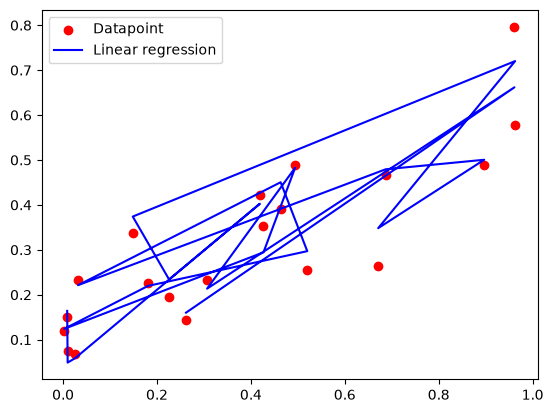

In [85]:
#   Plot the Linear Regression model


plt.scatter(X_test[0:20, 0], Y_test[0:20],
            color="Red", label="Datapoint")

plt.plot(X_test[0:20, 0], Y_pred[0:20],
         color="Blue", label="Linear regression")

plt.legend()
plt.show()

In [87]:
#    Z-score normalization


X = DF1.drop("Delivery_Time_min", axis=1).to_numpy()
Y = DF1[["Delivery_Time_min"]].to_numpy()

X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
Y = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)

In [88]:
#   Add another feature to X corresponding to bias


X = np.hstack((np.ones((X.shape[0], 1)), X))
X

array([[ 1.        , -0.37709844, -0.69075175, ..., -0.51657174,
        -0.33333333,  3.01786794],
       [ 1.        ,  1.11483666,  0.41445105, ..., -0.51657174,
        -0.33333333, -0.33135976],
       [ 1.        , -0.0976901 ,  1.51965386, ..., -0.51657174,
        -0.33333333, -0.33135976],
       ...,
       [ 1.        ,  0.97425384,  1.24335316, ..., -0.51657174,
         3.        , -0.33135976],
       [ 1.        ,  0.7194475 , -1.24335316, ..., -0.51657174,
        -0.33333333, -0.33135976],
       [ 1.        , -0.60554551,  0.96705245, ..., -0.51657174,
        -0.33333333, -0.33135976]], shape=(940, 9))

In [89]:
#   Weight or parameter initialization

theta = np.zeros(X.shape[1])
iterations = 1000

# Hyperparameters
learningrate = 0.01

# Gradient Descent
mseh = []

print(X.shape)
m = X.T
print(m.shape)

(940, 9)
(9, 940)


In [90]:
#   Gradient Descent


for i in range(iterations):
    y_pred = np.dot(X, theta)
    y_pred = y_pred.reshape(-1)
    Y = Y.reshape(-1)

    mse = mean_squared_error(Y, y_pred)
    mseh.append(mse)

    print(f"Iteration {i+1}: MSE = {mse}")

    gradient = np.dot(X.T, (y_pred-Y))/len(Y)
    theta -= learningrate * gradient

Iteration 1: MSE = 1.0000000000000002
Iteration 2: MSE = 0.9849445036009115
Iteration 3: MSE = 0.9701871728606765
Iteration 4: MSE = 0.955722024638937
Iteration 5: MSE = 0.9415431970937104
Iteration 6: MSE = 0.927644947199208
Iteration 7: MSE = 0.9140216483149095
Iteration 8: MSE = 0.9006677878048331
Iteration 9: MSE = 0.8875779647059463
Iteration 10: MSE = 0.8747468874447006
Iteration 11: MSE = 0.8621693716006833
Iteration 12: MSE = 0.849840337716409
Iteration 13: MSE = 0.8377548091522867
Iteration 14: MSE = 0.8259079099858251
Iteration 15: MSE = 0.8142948629541517
Iteration 16: MSE = 0.80291098743895
Iteration 17: MSE = 0.7917516974929267
Iteration 18: MSE = 0.7808124999069478
Iteration 19: MSE = 0.7700889923169988
Iteration 20: MSE = 0.7595768613501387
Iteration 21: MSE = 0.7492718808086384
Iteration 22: MSE = 0.7391699098915112
Iteration 23: MSE = 0.7292668914526544
Iteration 24: MSE = 0.7195588502948476
Iteration 25: MSE = 0.7100418914988549
Iteration 26: MSE = 0.7007121987869122


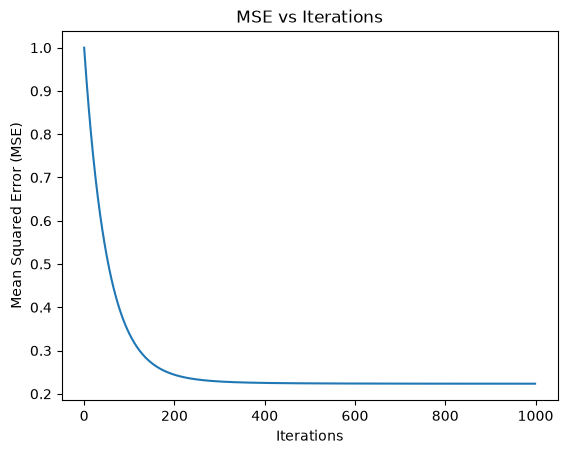

In [91]:

# Plot the MSE over iterations
plt.plot(range(iterations), mseh)
plt.xlabel('Iterations')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MSE vs Iterations')
plt.show()